## **MScFE 690 Capstone Project - Group 17836**
## **_"Dynamic Cross-Asset Replication of the S&P/ASX 200 VIX: Factor-Based and Regime-Aware ETF Portfolios"_**


In [1]:
import importlib.util
import itertools
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
import yfinance as yf
import seaborn as sns
import warnings
import cvxpy as cp

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNetCV

from hmmlearn import hmm

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
 

warnings.filterwarnings("ignore")

SEED =2026

PLOT_GRAPH = True

START_DATE = "2011-01-01"
END_DATE   = "2026-09-15"

TRANSACTION_COST = 0.001  # Fady: 0.1% includes: electronic trading and slippage 
SHORT_BORROW_RATE = 0.0025 # Fady: 0.25% borrowing rate to short Sector & Thematic ETF


TRN_WINDOW = 252
TST_WINDOW = 10
HMM_STATES = 3
VARIANCE_THRESHOLD = 0.99
MIN_ABS_WEIGHT = 0.01 
MIN_REL_WEIGHT_CHANGE = 0.02
WEIGHT_DEVIATION = 0.05 
PLS_COMPONENTS = 5

PLT_STRT = 2000 #0
PLT_SIZE = 500  #4000


### **Overview**
As part of our M2 project proposal submission, we outlined the code high level design steps which can be summarised as follows:
1. Data processing
2. Screening and elimination
3. Sliding window Walk-forward loop:

    3.1 Sliding window Walk-forward loop: Principal Component Regression (PCR)
   
    3.2 Sliding window Walk-forward loop: Partial Least Squares (PLS)
   
    3.3 Sliding window Walk-forward loop: Elastic Net Regression (EN)
   
5. Hidden Markov Model
6. Expanding window Walk-forward loop for HMM

In the next sections we will outline and implement each of these steps in details.

In [2]:
# Fady: Define reusable util functions
def walk_forward_sliding_window(dataset_length, train_window_size, test_window_size):
    splits = []
    train_start = 0

    while True:
        train_end = train_start + train_window_size - 1
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # slide both train and test windows forward
        train_start += test_window_size

    return pd.DataFrame(splits)

def walk_forward_expanding_window(dataset_length, initial_train_window_size, test_window_size):
    splits = []
    train_end = initial_train_window_size - 1

    while True:
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": 0,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # expand training window
        train_end += test_window_size

    return pd.DataFrame(splits)


def download_adjusted_prices(tickers, start, end):
    raw = yf.download( tickers,start=start, end=end, auto_adjust=False,actions=False, 
                      progress=False, group_by="column", threads=True )
    if raw.empty:
        raise RuntimeError("No price data were downloaded. Check internet access and ticker symbols.")

    if isinstance(raw.columns, pd.MultiIndex):
        fields = raw.columns.get_level_values(0)
        if "Adj Close" in fields:
            prices = raw["Adj Close"].copy()
        elif "Close" in fields:
            prices = raw["Close"].copy()
        else:
            raise RuntimeError("Could not find Adj Close or Close in Yahoo Finance output.")
    else:
        col = "Adj Close" if "Adj Close" in raw.columns else "Close"
        prices = raw[[col]].rename(columns={col: tickers[0]})

    prices = prices.sort_index()
    missing_cols = [c for c in tickers if c not in prices.columns]
    if missing_cols:
        raise RuntimeError(f"Missing downloaded tickers: {missing_cols}")

    prices = prices.reindex(columns=tickers)

    #prices = prices.ffill().dropna(how="any")
    return prices


def download_aud_usd(start_date=START_DATE, end_date=END_DATE):
    #Download AUD/USD Exchange Rate
    download_end = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

    prices = yf.download(
        "AUDUSD=X",
        start=start_date,
        end=download_end,
        auto_adjust=False,
        progress=False,
    )


    if prices.empty:
        raise ValueError("AUD/USD exchange-rate data could not be downloaded.")

    if "AUDUSD=X" in prices.columns:
        fx = prices["AUDUSD=X"].copy()
    else:
        fx = prices.iloc[:, 0].copy()

    fx.name = "AUDUSD"

    return fx

def convert_us_to_aud(price_df, aud_usd_series, us_tickers):
    converted_df = price_df.copy()

    fx = aud_usd_series.reindex(converted_df.index).ffill(limit=20)

    for ticker in us_tickers:
        if ticker in converted_df.columns:
            converted_df[ticker] = converted_df[ticker] / fx

    return converted_df

def get_ranked_pairwise_correlations(corr_matrix):
    """Returns unique pairwise correlations sorted highest to lowest."""
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1,
    )

    corr_pairs = corr_matrix.where(mask).stack()
    corr_pairs.index.names = ["Ticker_1", "Ticker_2"]
    corr_pairs = corr_pairs.sort_values(ascending=False)

    return corr_pairs


def walk_forward_reconst(y_pred,orig_price,splits):
    #reconstruct A-VIX prices from A-VIX precentage change predictions

    reconst = []
    pred_offset = 0

    for split in splits.itertuples():

        segment_size = split.test_end - split.test_start + 1
        segment_pred = np.asarray(y_pred[pred_offset:pred_offset+segment_size])

        # A return at test_start is relative to the previous day's A-VIX level
        segment = list(orig_price.values[split.test_start-1]*np.cumprod(1+segment_pred))
        reconst.extend(segment)
        pred_offset += segment_size

    return np.clip(reconst,0,100)

def focused_plot(title,reconstructed,orig_price,strt=PLT_STRT,sz=PLT_SIZE):
    # Zoom in window for visual assessment
    plt.clf()
    plt.figure(figsize=(14,6))
    dates = orig_price.index[strt:strt+sz]
    plt.plot(dates, orig_price.values[strt:strt+sz], label='Actual', linewidth=2)
    plt.plot(dates, reconstructed[strt:strt+sz], label= title+' Predicted', alpha=0.8)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.title("Actual vs "+title)
    plt.xlabel("Date")
    plt.tight_layout()
    plt.show()

### **1. Data Processing**
- Download all candidate securities from the invetsment universe (Jan 2019 – Sep 2026)
- Align dates for US: The prices observed in Australia can only be upto the previous day in US.
- Convert USD prices to AUD at daily exchange rate for US securties.
- handle missing data
- compute A-VIX daily percentage change 
- Compute securties daily returns
- Standardize returns



In [3]:
#Investment Universe
tickers_dict = pd.read_csv('investment_universe_dictionary.csv')
US_TICKERS = list(tickers_dict[tickers_dict.Region=='US']['Ticker'].values)
AU_TICKERS = list(tickers_dict[tickers_dict.Region=='AU']['Ticker'].values)
ALL_TICKERS = list(tickers_dict['Ticker'].values)

universe_prices= download_adjusted_prices(ALL_TICKERS, START_DATE, END_DATE)

# Fady: Australia can only observe the previous day in US
for clm in US_TICKERS:
    universe_prices[clm] = universe_prices[clm].shift(1)
    
    
aud_usd = download_aud_usd(start_date=START_DATE, end_date=END_DATE)
universe_aud_prices = convert_us_to_aud(universe_prices, aud_usd, US_TICKERS )

print('\n\n')
display(universe_aud_prices)

Ticker,^AXVI,STW.AX,IOZ.AX,BEAR.AX,QFN.AX,OZF.AX,QRE.AX,VAP.AX,GOLD.AX,OOO.AX,...,TECH.AX,ROBO.AX,MVA.AX,IFRA.AX,MICH.AX,GOVT.AX,AAA.AX,BILL.AX,BBUS.AX,VIXM
Date,,,,,,,,,,,,,,,,,,,,,
2011-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-04,17.910000,24.837637,11.139848,NaN,4.883819,NaN,4.383834,25.167927,13.650000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-01-05,17.490000,24.637602,11.084836,NaN,4.883819,NaN,4.367618,25.235622,13.430000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.202897
2011-01-06,16.860001,24.670931,11.051829,NaN,4.883819,NaN,4.329780,25.386642,13.424000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,313.671387
2011-01-07,16.320000,24.587591,11.029826,NaN,4.883819,NaN,4.313563,25.256453,13.425000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,316.439667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-08,11.970000,79.519974,36.099998,7.32,17.639999,29.780001,10.720000,84.980606,55.889999,9.68,...,116.169998,89.629997,22.040001,24.691797,2.98,23.816469,49.927879,100.410004,22.240000,NaN
2026-09-09,11.750000,79.539742,36.110001,7.31,17.490000,29.559999,10.790000,84.751541,55.580002,9.70,...,114.800003,89.260002,21.840000,24.820763,3.00,23.776793,49.927879,100.470001,22.330000,18.530831
2026-09-10,13.140000,78.591309,35.700001,7.41,17.280001,29.200001,10.690000,83.855225,56.000000,9.88,...,114.059998,89.199997,21.420000,24.652117,2.98,23.717276,49.947807,100.459999,22.520000,18.529548


In [4]:
universe_returns = universe_aud_prices.ffill().pct_change()

corr_matrix = universe_returns.corr()
ranked_corr_pairs = get_ranked_pairwise_correlations(corr_matrix)
ranked_corr_pairs.to_csv('ranked_pairs.csv')

print('\n\n Top positive correlations')
display(ranked_corr_pairs.head(20))
print('\n\n Top negative correlations')
display(ranked_corr_pairs.tail(20))
print('\n\n')




 Top positive correlations


Ticker_1  Ticker_2
VIXY      UVXY        0.985324
STW.AX    VAS.AX      0.932816
VIXY      VIXM        0.922306
IOZ.AX    VAS.AX      0.921648
SPY       QQQ         0.915656
UVXY      VIXM        0.901407
STW.AX    IOZ.AX      0.901044
WBC.AX    ANZ.AX      0.852526
          NAB.AX      0.852245
VAF.AX    CRED.AX     0.844276
VGB.AX    CRED.AX     0.844079
BHP.AX    OZR.AX      0.835938
          RIO.AX      0.835418
NAB.AX    ANZ.AX      0.832703
LQD       TLT         0.822795
IAF.AX    CRED.AX     0.814791
OZR.AX    MVR.AX      0.814128
TECH.AX   ROBO.AX     0.804068
QRE.AX    MVR.AX      0.796203
VAP.AX    SLF.AX      0.792269
dtype: float64



 Top negative correlations


Ticker_1  Ticker_2
UVXY      EWA        -0.565664
BEAR.AX   QRE.AX     -0.584823
VIXY      EWA        -0.589191
BEAR.AX   MVR.AX     -0.604322
          VAP.AX     -0.616129
          BHP.AX     -0.619139
          OZR.AX     -0.622305
SVXY      VIXM       -0.696892
BEAR.AX   MQG.AX     -0.715173
          QFN.AX     -0.715231
          WBC.AX     -0.726704
          ANZ.AX     -0.729158
          CBA.AX     -0.730169
          NAB.AX     -0.731761
          OZF.AX     -0.733338
VIXY      SVXY       -0.799452
UVXY      SVXY       -0.820048
IOZ.AX    BEAR.AX    -0.920914
BEAR.AX   VAS.AX     -0.949541
STW.AX    BEAR.AX    -0.953898
dtype: float64

### **2. Screening and elimination**
The next step is narrow down the investment universe based on the returns correlation results. We applied two screening rules:
- Check correlation matrix and for highly correlated pairs > 0.9, drop the one with the newer inception date.
- Check correlation with A-VIX precentage change and drop the ones with weak absolute correlation values below 0.01 as they will have very low linear predictive power.


In [5]:
drp_clm = [ # High corr to others
            'VIXY','IOZ.AX','VAS.AX','QRE.AX','VGB.AX','VAF.AX',
            'QFN.AX','SPY','VIXM','QRE.AX','VAP.AX',
            'MVR.AX', 'WBC.AX', 'ANZ.AX', 'NAB.AX','RIO.AX','DRUG.AX',
           
            # low AVIX corr           
           'LQD','GLD','BBUS.AX','BILL.AX','BBOZ.AX','HYG','USO',
           'CRED.AX','IAF.AX','GOVT.AX','IXC.AX','OOO.AX',
           'ILB.AX', 'XRO.AX',
    ]

screened_prices= universe_aud_prices.drop(drp_clm, axis =1)
screened_returns = universe_returns.drop(drp_clm, axis =1)

# Prepare for modeling
screened_prices.bfill(inplace=True)
screened_returns.fillna(0.0,inplace=True)

X = screened_returns.copy().drop(['^AXVI','AAA.AX'], axis =1)      # predictors dataframe
y = screened_returns['^AXVI'].copy()    # target series

trn_features = X.columns

### **3. Sliding window Walk forward loop**
For each of the three models we will apply the following steps:
1. Split the data and generate the train and test pairs
2. Fit the model on the training window data
3. Predict the test window A-VIX precentage change
4. Reconstruct the A-VIX level from the predicted precentage change
5. Calculate different tracking error metrics on test window.
6. Calculate the individual securties coeffcients from the factor coefficents.
7. Define portfolio weight constraints guided by the regressions coeffcients after normalisation.
8. Conduct QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
9. Predict portfolio returns over the test window
10. Calculate trading metrics for the rebalancing at the end of the test window

In [6]:
# Fady: define PCR, PLS, Elastic Net functions and the sliding window loop

def PCR_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # PCA
    pca = PCA()
    Xtrn_pca = pca.fit_transform(Xtrn_scaled)
    Xtst_pca = pca.transform(Xtst_scaled)

    # Explained variance
    explained_var = pca.explained_variance_ratio_
    cum_var = np.cumsum(explained_var)
    n_components = np.argmax(cum_var >= VARIANCE_THRESHOLD) + 1
    Xtrn_pca_selected = Xtrn_pca[:, :n_components]
    Xtst_pca_selected = Xtst_pca[:, :n_components]

    #print(f"Selected PCs: {n_components}")
    #print(f"Cumulative variance explained: {cum_var[n_components-1]:.3f}")

    #PCR
    pcr = LinearRegression(fit_intercept=True)
    pcr.fit(Xtrn_pca_selected, y_train)
    y_pred = pcr.predict(Xtst_pca_selected)

    return y_pred,n_components,pcr,pca,scaler


def PLS_fit_predict(X_train,y_train,X_test,ncomponents):

    ncomponents = max(1, min(ncomponents, X_train.shape[1], len(X_train)))

    # PLSRegression centres X and y and therefore fits an intercept.
    pls = PLSRegression(n_components=ncomponents, scale=True)
    pls.fit(X_train, y_train)
    y_pred = pls.predict(X_test).ravel()

    return y_pred,pls


def EN_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # Elastic Net
    model = ElasticNetCV(
        l1_ratio=[0.001, 0.005, 0.01],
        alphas = [0.005, 0.01],
        cv=3,
        max_iter=200,
        fit_intercept=True,
        random_state=SEED  )

    model.fit(Xtrn_scaled, y_train)
    y_pred = model.predict(Xtst_scaled)

    '''
    print("\nEN Hyperparameters")
    print(f"Alpha    = {model.alpha_:.6f}")
    print(f"L1 Ratio = {model.l1_ratio_:.3f}")
    '''
    return y_pred,model,scaler


def convert_to_security_coefficients(title,model,trn_features,scaler=None,pca=None):

    features = list(trn_features)

    if title == 'PCR':
        pc_coefficients = np.asarray(model.coef_).ravel()
        pca_components = pca.components_[:len(pc_coefficients),:]

        scaled_coefficients = np.dot(pca_components.T,pc_coefficients)
        security_coefficients = scaled_coefficients/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(pca.mean_,scaled_coefficients)
        intercept -= np.dot(scaler.mean_,security_coefficients)

    elif title == 'PLS':
        # Convert PLS latent-factor coefficients back to the original securities.
        factor_coefficients = np.dot(model.x_rotations_,model.y_loadings_.T)
        security_coefficients = (
            (factor_coefficients*model._y_std).T/model._x_std
        ).ravel()

        intercept = float(np.asarray(model._y_mean).ravel()[0])
        intercept -= np.dot(model._x_mean,security_coefficients)

    elif title == 'EN':
        security_coefficients = np.asarray(model.coef_).ravel()/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(scaler.mean_,security_coefficients)

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    coefficients = pd.DataFrame(
        [list(security_coefficients)+[intercept]],
        columns=features+['CONST']
    )

    return coefficients


def predict_from_securities(X_test,coefficients):
    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    security_coefficients = coefficients[security_columns].iloc[0].values
    intercept = coefficients['CONST'].iloc[0]

    y_pred = np.dot(X_test[security_columns].values,security_coefficients)+intercept

    return y_pred


# cache of model fits. A fit only depends on the window (and HMM state), the model and its
# own parameter, so grid-search iterations re-use identical fits.
FIT_CACHE = {}


def fit_predict_securities(title,X_train,y_train,X_test,ncomponents=20,window_key=None):

    # Fady: fit the model, convert its coefficients to individual securities and check
    # that the security coefficients give the same test-window prediction.
    if title == 'PCR':
        model_parameter = VARIANCE_THRESHOLD
    elif title == 'PLS':
        model_parameter = ncomponents
    else:
        model_parameter = None

    cache_key = None if window_key is None else (title,model_parameter)+tuple(window_key)

    if cache_key is not None and cache_key in FIT_CACHE:
        ypred,coefficient_values,pcr_ncomponents = FIT_CACHE[cache_key]
        coefficients = pd.DataFrame([list(coefficient_values)],columns=list(X_train.columns)+['CONST'])

        return ypred,coefficients,pcr_ncomponents

    pcr_ncomponents = None

    if title == 'PCR':
        ypred,pcr_ncomponents,pcr,pca,scaler = PCR_fit_predict(X_train,y_train,X_test)

        coefficients = convert_to_security_coefficients(
            'PCR',pcr,X_train.columns,scaler=scaler,pca=pca
        )

    elif title == 'PLS':
        ypred,pls = PLS_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PLS',pls,X_train.columns
        )

    elif title == 'EN':
        ypred,model,scaler = EN_fit_predict(X_train,y_train,X_test)

        coefficients = convert_to_security_coefficients(
            'EN',model,X_train.columns,scaler=scaler
        )

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    ypred_from_securities = predict_from_securities(X_test,coefficients)

    if not np.allclose(ypred,ypred_from_securities,rtol=1e-7,atol=1e-10):
        raise RuntimeError(title+" security coefficient conversion changed ypred.")

    if cache_key is not None:
        FIT_CACHE[cache_key] = (ypred,coefficients.iloc[0].values.copy(),pcr_ncomponents)

    return ypred,coefficients,pcr_ncomponents



def coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=MIN_ABS_WEIGHT):

    # Fady: CONST is the regression intercept and is not a portfolio holding
    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    beta = coefficients[security_columns].iloc[0].values.astype(float).copy()

    if min_abs_weight < 0:
        raise ValueError("min_abs_weight cannot be negative.")

    # Fady: remove very small security weights and re-normalise the remaining coefficients to improve sparsity.
    
    while True:
        gross_beta = np.sum(np.abs(beta))

        if gross_beta == 0:
            raise ValueError("Security coefficients cannot all be zero.")

        risky_weights = gross_exposure*beta/gross_beta

        small_weights = (np.abs(risky_weights) < min_abs_weight) & (beta != 0)

        if not np.any(small_weights):
            break

        beta[small_weights] = 0.0

    # AAA.AX is the residual cash position so that total portfolio weight = 1
    cash_weight = 1.0 - np.sum(risky_weights)

    weights = pd.DataFrame(
        [list(risky_weights)+[cash_weight]],
        columns=security_columns+['AAA.AX']
    )

    return weights


# one cvxpy problem per number of securities, built once and re-solved with new
# parameter values. 
QP_PROBLEMS = {}


def build_QP_problem(n_securities):

    weights_qp = cp.Variable(n_securities)
    aaa_weight_qp = cp.Variable()

    R_securities = cp.Parameter((n_securities+1,n_securities))
    R_aaa = cp.Parameter(n_securities+1)
    Qt_y = cp.Parameter(n_securities+1)
    lower_bounds = cp.Parameter(n_securities)
    upper_bounds = cp.Parameter(n_securities)
    gross_exposure = cp.Parameter(nonneg=True)

    objective = cp.Minimize(
        cp.sum_squares(R_securities@weights_qp + R_aaa*aaa_weight_qp - Qt_y)
    )

    constraints = [
        cp.sum(weights_qp)+aaa_weight_qp == 1,
        cp.norm1(weights_qp) <= gross_exposure,
        weights_qp >= lower_bounds,
        weights_qp <= upper_bounds,
    ]

    problem = cp.Problem(objective,constraints)


    if not problem.is_dpp():
        print("Note: the QP is not DPP-compliant, cvxpy will re-compile it for every solve.")

    qp_problem = {
        'problem': problem,
        'weights_qp': weights_qp,
        'aaa_weight_qp': aaa_weight_qp,
        'R_securities': R_securities,
        'R_aaa': R_aaa,
        'Qt_y': Qt_y,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'gross_exposure': gross_exposure,
    }

    return qp_problem


def QP_optimize_weights(X_train,y_train,aaa_returns,portfolio_weights,gross_exposure=1.0):

    # Fady: optimise the statistically derived weights while keeping each
    # risky-security weight within +/- WEIGHT_DEVIATION of its original value.
    features = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']

    initial_weights = portfolio_weights[features].iloc[0].values.astype(float)

    X_values = X_train[features].values
    y_values = np.asarray(y_train).ravel()
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(y_values) or len(y_values) != len(aaa_values):
        raise ValueError("X_train, y_train and aaa_returns must have the same number of observations.")

    lower_bounds = initial_weights - WEIGHT_DEVIATION*np.abs(initial_weights)
    upper_bounds = initial_weights + WEIGHT_DEVIATION*np.abs(initial_weights)

    lower_bounds = np.where(initial_weights > 0,np.maximum(lower_bounds,MIN_ABS_WEIGHT),lower_bounds)
    upper_bounds = np.where(initial_weights < 0,np.minimum(upper_bounds,-MIN_ABS_WEIGHT),upper_bounds)

    # Fady: securities removed by coefficients_to_weights() stay at zero during QP optimisation.
    zero_weights = np.isclose(initial_weights,0.0)
    lower_bounds[zero_weights] = 0.0
    upper_bounds[zero_weights] = 0.0

    design = np.column_stack([X_values,aaa_values])
    n_missing_rows = design.shape[1]-len(design)

    if n_missing_rows > 0:
        design = np.vstack([design,np.zeros((n_missing_rows,design.shape[1]))])
        y_values = np.concatenate([y_values,np.zeros(n_missing_rows)])

    Q,R = np.linalg.qr(design)

    if len(features) not in QP_PROBLEMS:
        QP_PROBLEMS[len(features)] = build_QP_problem(len(features))

    qp_problem = QP_PROBLEMS[len(features)]
    qp_problem['R_securities'].value = R[:,:-1]
    qp_problem['R_aaa'].value = R[:,-1]
    qp_problem['Qt_y'].value = Q.T@y_values
    qp_problem['lower_bounds'].value = lower_bounds
    qp_problem['upper_bounds'].value = upper_bounds
    qp_problem['gross_exposure'].value = gross_exposure

    problem = qp_problem['problem']
    #problem.solve(warm_start=True) # Fady: speed up
    problem.solve()

    if problem.status not in ['optimal','optimal_inaccurate']:
        raise RuntimeError("QP optimisation failed with status: "+str(problem.status))

    risky_qp_weights = np.clip(np.asarray(qp_problem['weights_qp'].value).ravel(),lower_bounds,upper_bounds)
    aaa_qp_weight = 1.0-np.sum(risky_qp_weights)

    qp_weights = pd.DataFrame(
        [list(risky_qp_weights)+[float(aaa_qp_weight)]],
        columns=features+['AAA.AX']
    )

    return qp_weights



def execute_portfolio_trading(portfolio_weights,previous_weights=None,transaction_cost=TRANSACTION_COST,
                              rebalance_opportunities=None,min_rel_weight_chng=MIN_REL_WEIGHT_CHANGE):

    # Fady: portfolio_weights contains one row for each day in the test window.
    # At the first day compare with the last portfolio of the previous test window.
    if min_rel_weight_chng < 0:
        raise ValueError("min_rel_weight_chng cannot be negative.")

    weights = portfolio_weights.values.astype(float)

    if previous_weights is None:
        # Initial portfolio starts fully invested in AAA.AX.
        previous = pd.Series(0.0,index=portfolio_weights.columns)
        previous['AAA.AX'] = 1.0
    else:
        previous = previous_weights.iloc[-1].reindex(portfolio_weights.columns).astype(float)

    if rebalance_opportunities is None:
        rebalance_opportunities = np.zeros(len(weights),dtype=bool)
        if len(weights) > 0:
            rebalance_opportunities[0] = True

    rebalance_opportunities = np.asarray(rebalance_opportunities,dtype=bool)

    if len(rebalance_opportunities) != len(weights):
        raise ValueError("rebalance_opportunities must have the same length as portfolio_weights.")

    risky_columns = np.array([clm != 'AAA.AX' for clm in portfolio_weights.columns])

    # Fady: all weight changes are executed, including small ones, so each day's
    # portfolio becomes the previous portfolio of the next day.
    previous_values = np.vstack([previous.values,weights[:-1]])[:len(weights)]
    weight_change = weights-previous_values

    # Fady: very small weight changes are executed for mathemtical correctness but do not attract transaction
    # cost and are not counted as trades because in reality Portfolio mangers will skip them

    weight_tolerance = 1e-8
    traded = (np.abs(weight_change) > weight_tolerance) & (np.abs(weight_change) >= min_rel_weight_chng*np.abs(previous_values))
    charged_weight_change = np.where(traded,weight_change,0.0)

    # 1-D sum per day (not axis=1) so the summation order, and the result, are exactly as before
    risky_turnover = np.array([np.sum(np.abs(day_change[risky_columns])) for day_change in charged_weight_change])
    total_turnover = np.array([np.sum(np.abs(day_change)) for day_change in charged_weight_change])

    trading = pd.DataFrame(
        {
            'risky_turnover': risky_turnover,
            'total_turnover': total_turnover,
            'transaction_cost': transaction_cost*total_turnover,
            'rebalance_required': np.any(traded,axis=1),
            'rebalance_opportunity': rebalance_opportunities,
            'number_trades': np.sum(traded,axis=1),
            'active_holdings': np.sum(np.abs(weights[:,risky_columns]) >= MIN_ABS_WEIGHT,axis=1),
        },
        index=portfolio_weights.index
    )

    return trading


def compute_trading_metrics(title,trading,net_returns,gross_returns,verbose=True):

    if len(trading) == 0:
        raise ValueError("trading cannot be empty.")

    number_days = len(trading)
    
    net_returns = np.asarray(net_returns,dtype=np.float64)
    gross_returns = np.asarray(gross_returns,dtype=np.float64)
    
    net_annualised_returns = np.sum(net_returns)*252/number_days
    gross_annualised_returns = np.sum(gross_returns)*252/number_days
    
    rebalance_days = int(trading['rebalance_required'].sum())
    rebalance_opportunities = int(trading['rebalance_opportunity'].sum())

    total_transaction_cost = trading['transaction_cost'].sum()
    total_turnover = trading['total_turnover'].sum()
    total_risky_turnover = trading['risky_turnover'].sum()

    if rebalance_opportunities > 0:
        turnover_ratio = total_risky_turnover*252/number_days
    else:
        turnover_ratio = 0.0

    annualised_transaction_cost = total_transaction_cost*252/number_days

    # annualised_total_cost = annualised_transaction_cost + annualised_short_borrow_cost
    # = gross_annualised_returns - net_annualised_returns
    annualised_total_cost = np.sum(gross_returns-net_returns)*252/number_days
    annualised_short_borrow_cost = annualised_total_cost-annualised_transaction_cost

    if rebalance_days > 0:
        average_turnover_rebalance = total_turnover/rebalance_days
        average_transaction_cost_rebalance = total_transaction_cost/rebalance_days
    else:
        average_turnover_rebalance = 0.0
        average_transaction_cost_rebalance = 0.0

    maximum_daily_turnover = trading['risky_turnover'].max()
    number_trades = int(trading['number_trades'].sum())
    average_active_holdings = trading['active_holdings'].mean()

    if verbose:
        print("\n"+title)
        print("-" * 30)
        print(f"Annualised gross returns\t\t: {gross_annualised_returns:.6f}")
        print(f"Annualised net returns\t\t\t: {net_annualised_returns:.6f}")
        print(f"Annualised Transaction Cost\t\t: {annualised_transaction_cost:.6f}")
        print(f"Annualised Short Borrow Cost\t: {annualised_short_borrow_cost:.6f}")
        print(f"Annualised Total Cost\t\t\t: {annualised_total_cost:.6f}")
        print(f"Turnover ratio\t\t\t\t\t: {turnover_ratio:.6f}")
        #print(f"Total turnover\t\t\t: {total_turnover:.6f}")
        print(f"Rebalance days\t\t\t\t\t: {rebalance_days}")
        print(f"Rebalance opportunities\t\t\t: {rebalance_opportunities}")
        print(f"Number of trades\t\t\t\t: {number_trades}")
        #print(f"Average turnover / rebalance\t: {average_turnover_rebalance:.6f}")
        print(f"Maximum daily turnover\t\t\t: {maximum_daily_turnover:.6f}")
        #print(f"Total transaction cost\t\t: {total_transaction_cost:.6f}")
        #print(f"Average cost / rebalance\t: {average_transaction_cost_rebalance:.6f}")
        print(f"Average active holdings\t\t\t: {average_active_holdings:.2f}")

    metrics = {
        'gross_annualised_returns':gross_annualised_returns,
        'net_annualised_returns':net_annualised_returns,
        'annualised_transaction_cost': annualised_transaction_cost,
        'annualised_short_borrow_cost': annualised_short_borrow_cost,
        'annualised_total_cost': annualised_total_cost,
        'turnover_ratio': turnover_ratio,
        #'total_turnover': total_turnover,
        'total_risky_turnover': total_risky_turnover,
        'rebalance_days': rebalance_days,
        'rebalance_opportunities': rebalance_opportunities,
        'number_trades': number_trades,
        #'average_turnover_rebalance': average_turnover_rebalance,
        'maximum_daily_turnover': maximum_daily_turnover,
        #'total_transaction_cost': total_transaction_cost,
        #'average_transaction_cost_rebalance': average_transaction_cost_rebalance,
        'average_active_holdings': average_active_holdings,
    }
    
    
    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics


def compute_portfolio_returns(qp_weights,X_test,aaa_returns,short_borrow_rate=SHORT_BORROW_RATE,transaction_costs=None):

    # Fady: weights may be one constant row for the whole test window or
    # one row per day when the HMM state changes inside the test window.
    features = [clm for clm in qp_weights.columns if clm != 'AAA.AX']

    X_values = X_test[features].values
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(aaa_values):
        raise ValueError("X_test and aaa_returns must have the same number of observations.")

    if len(qp_weights) == 1:
        risky_weights = np.tile(
            qp_weights[features].iloc[0].values.astype(float),
            (len(X_test),1)
        )
        aaa_weights = np.repeat(
            float(qp_weights['AAA.AX'].iloc[0]),
            len(X_test)
        )

    elif len(qp_weights) == len(X_test):
        risky_weights = qp_weights[features].values.astype(float)
        aaa_weights = qp_weights['AAA.AX'].values.astype(float)

    else:
        raise ValueError("qp_weights must contain either one row or one row per test observation.")

    # Cash component remains invested in AAA.AX.
    portfolio_return = np.sum(X_values*risky_weights,axis=1) + aaa_values*aaa_weights

    # Apply daily short borrowing cost to the total short security exposure.
    total_short_positions = np.sum(np.abs(np.minimum(risky_weights,0)),axis=1)
    daily_short_borrow_rate = short_borrow_rate/252
    short_borrow_cost = total_short_positions*daily_short_borrow_rate

    if transaction_costs is None:
        transaction_costs = np.zeros(len(X_test))
    else:
        transaction_costs = np.asarray(transaction_costs).ravel()

        if len(transaction_costs) != len(X_test):
            raise ValueError("transaction_costs must have the same number of observations as X_test.")

    y_pred_portfolio = portfolio_return-short_borrow_cost-transaction_costs

    return y_pred_portfolio, portfolio_return


def compute_tracking_metrics(title,y_test,y_pred):
    y_test = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(y_test) != len(y_pred):
        raise ValueError("y_test and y_pred must have the same length.")
    if len(y_test) < 2:
        raise ValueError("At least two observations are required to calculate tracking metrics.")

    T = len(y_test)
    active_return = y_pred - y_test
    #index_minus_portfolio = y_test - y_pred

    #r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    # Dorocakova (2017), p.159
    TE1_Dorocakova = np.sqrt(np.sum(active_return**2)/(T-1))
    TE2_Dorocakova = np.mean(np.abs(active_return))
    RD_Dorocakova = np.abs(active_return)
    TE3_Dorocakova = np.std(RD_Dorocakova, ddof=1)

    print("\n"+title)
    print("-" * 30)
    
    #print(f"R²   : {r2:.4f}")
    print(f"MAE\t\t\t\t: {mae:.4f}")
    print(f"RMSE\t\t\t: {rmse:.6f}")

    #print("\nDorocakova's metrics")
    print(f"TE1_Dorocakova : {TE1_Dorocakova:.6f}")
    print(f"TE2_Dorocakova : {TE2_Dorocakova:.6f}")
    print(f"TE3_Dorocakova : {TE3_Dorocakova:.6f}")

    
    metrics = {
        'MAE': mae,
        'RMSE': rmse,
        'TE1': TE1_Dorocakova,
        'TE2': TE2_Dorocakova,
        'TE3': TE3_Dorocakova,

    }
    
    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics





def sliding_walk_forward(title,X_df,y_df,orig_price,train_window_size,test_window_size,ncomponents=PLS_COMPONENTS):

    y_pred = []
    y_pred_portfolio = []  #net portfolio returns (after costs)
    y_pred_portfolio_gross = [] #gross portfolio returns
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None

    splits=walk_forward_sliding_window(len(X_df), train_window_size, test_window_size)

    for split in splits.itertuples():

        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        window_key = ('sliding',split.train_start,split.train_end,split.test_start,split.test_end)

        ypred,coefficients,ncomponents_used = fit_predict_securities(
            title,X_train,y_train,X_test,ncomponents,window_key=window_key
        )

        if ncomponents_used is not None:
            pcr_ncomponents.append(ncomponents_used)

        portfolio_weights = coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=MIN_ABS_WEIGHT)

        aaa_train = screened_returns.loc[X_train.index,'AAA.AX']
        qp_weights = QP_optimize_weights(
            X_train,y_train,aaa_train,portfolio_weights,gross_exposure=1.0
        )

        # Fady: sliding-window QP weights stay unchanged during the test window.
        daily_qp_weights = pd.DataFrame(
            np.tile(qp_weights.iloc[0].values,(len(X_test),1)),
            index=X_test.index,
            columns=qp_weights.columns
        )

        rebalance_opportunities = np.zeros(len(X_test),dtype=bool)
        rebalance_opportunities[0] = True

        trading = execute_portfolio_trading(
            daily_qp_weights,previous_qp_weights,transaction_cost=TRANSACTION_COST,
            rebalance_opportunities=rebalance_opportunities,min_rel_weight_chng=MIN_REL_WEIGHT_CHANGE
        )
        trading_records.append(trading)

        aaa_test = screened_returns.loc[X_test.index,'AAA.AX']
        ypred_portfolio, ypred_portfolio_gross = compute_portfolio_returns(
            daily_qp_weights,X_test,aaa_test,short_borrow_rate=SHORT_BORROW_RATE,
            transaction_costs=trading['transaction_cost'].values
        )
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))

        previous_qp_weights = daily_qp_weights.iloc[[-1]].copy()

        y_pred.extend(list(ypred))

    # reconstruction from actual QP portfolio returns
    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross



#### **3.1 Principal Component Regression (PCR)**



[PCR] total returns
------------------------------
MAE				: 0.0445
RMSE			: 0.067035
TE1_Dorocakova : 0.067044
TE2_Dorocakova : 0.044483
TE3_Dorocakova : 0.050157

[PCR] net retruns
------------------------------
MAE				: 0.0445
RMSE			: 0.067036
TE1_Dorocakova : 0.067044
TE2_Dorocakova : 0.044477
TE3_Dorocakova : 0.050162

[PCR] Trading
------------------------------
Annualised gross returns		: -0.002595
Annualised net returns			: -0.011578
Annualised Transaction Cost		: 0.007522
Annualised Short Borrow Cost	: 0.001462
Annualised Total Cost			: 0.008984
Turnover ratio					: 6.537891
Rebalance days					: 380
Rebalance opportunities			: 380
Number of trades				: 7747
Maximum daily turnover			: 1.509858
Average active holdings			: 19.97


<Figure size 640x480 with 0 Axes>

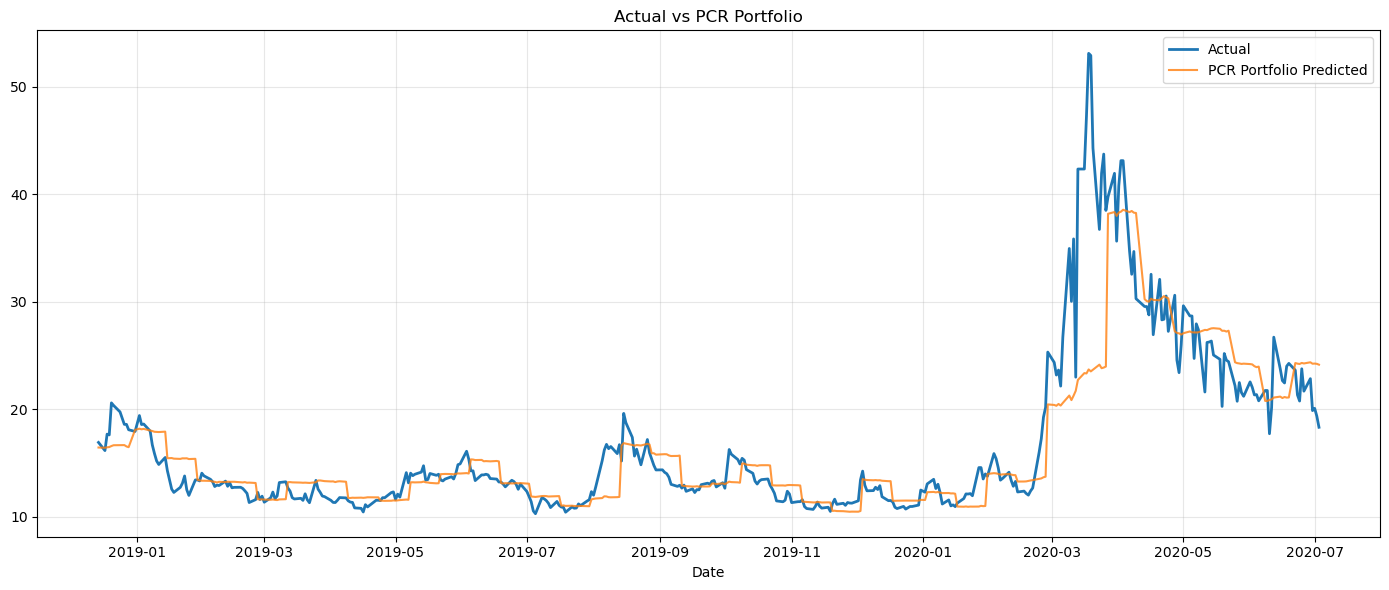

In [7]:
###################
# PCR
###################

y_pred_pcr, y_pred_portfolio_pcr, reconst_pcr, pcr_components, pcr_coeff, pcr_weights, pcr_qp_weights, pcr_trading, gross_returns_pcr = sliding_walk_forward('PCR',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr)

metrics_portfolio_pcr = compute_tracking_metrics('[PCR] total returns',y.iloc[pred_start:pred_end].values,gross_returns_pcr)
metrics_portfolio_pcr = compute_tracking_metrics('[PCR] net retruns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr)
metrics_trading_pcr = compute_trading_metrics('[PCR] Trading',pcr_trading,y_pred_portfolio_pcr,gross_returns_pcr)
pcr_objective = metrics_trading_pcr.loc[metrics_trading_pcr['Metric']=='net_annualised_returns', 'Value'].values[0]


if PLOT_GRAPH ==True:
    PLT_STRT = 1800 #0
    PLT_SIZE = 400  #4000
    focused_plot('PCR Portfolio',reconst_pcr,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)

    

#### **3.2 Partial Least Squares (PLS)**



[PLS] total retruns
------------------------------
MAE				: 0.0445
RMSE			: 0.067096
TE1_Dorocakova : 0.067104
TE2_Dorocakova : 0.044511
TE3_Dorocakova : 0.050212

[PLS] net retruns
------------------------------
MAE				: 0.0445
RMSE			: 0.067097
TE1_Dorocakova : 0.067106
TE2_Dorocakova : 0.044505
TE3_Dorocakova : 0.050219

[PLS] Trading
------------------------------
Annualised gross returns		: 0.000530
Annualised net returns			: -0.007493
Annualised Transaction Cost		: 0.006558
Annualised Short Borrow Cost	: 0.001464
Annualised Total Cost			: 0.008023
Turnover ratio					: 5.700915
Rebalance days					: 380
Rebalance opportunities			: 380
Number of trades				: 7578
Maximum daily turnover			: 1.358101
Average active holdings			: 19.79


<Figure size 640x480 with 0 Axes>

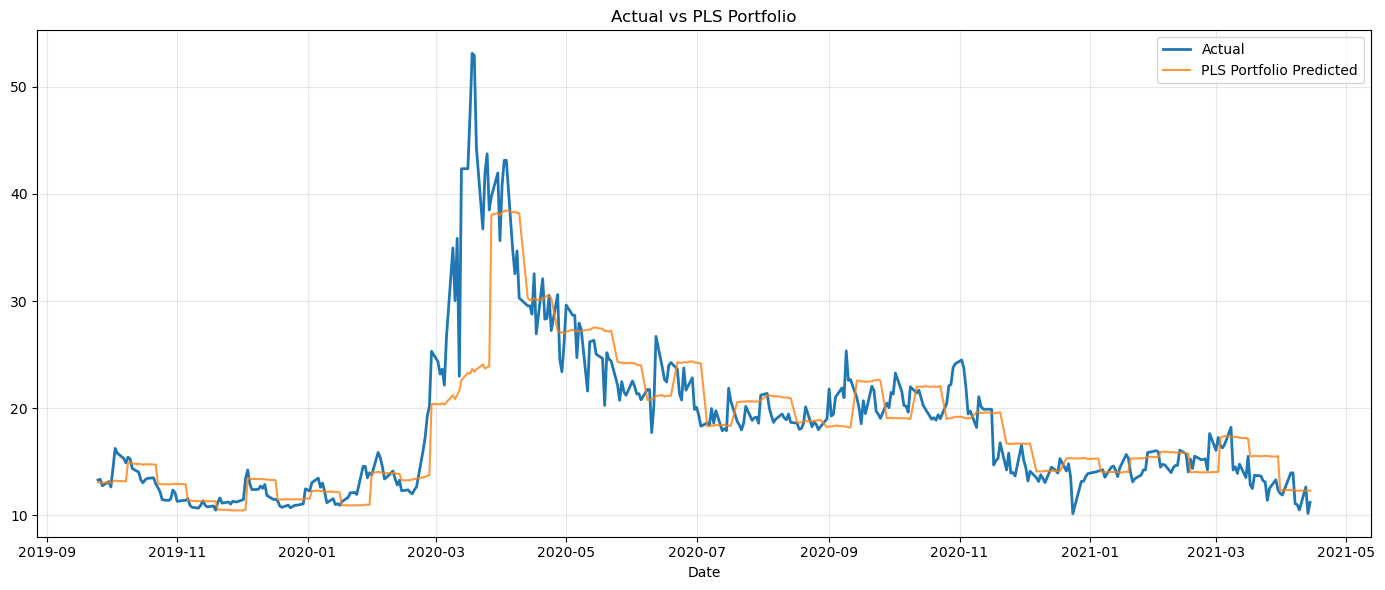

In [8]:
###################
# PLS
###################

y_pred_pls, y_pred_portfolio_pls, reconst_pls, pls_components, pls_coeff, pls_weights, pls_qp_weights, pls_trading,gross_returns_pls = sliding_walk_forward('PLS',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=PLS_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls)

metrics_portfolio_pls = compute_tracking_metrics('[PLS] total retruns',y.iloc[pred_start:pred_end].values,gross_returns_pls)
metrics_portfolio_pls = compute_tracking_metrics('[PLS] net retruns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls)
metrics_trading_pls = compute_trading_metrics('[PLS] Trading',pls_trading,y_pred_portfolio_pls,gross_returns_pls)
pls_objective = metrics_trading_pls.loc[metrics_trading_pls['Metric']=='net_annualised_returns', 'Value'].values[0]

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 400  #4000
    focused_plot('PLS Portfolio',reconst_pls,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)
   

#### **3.3 Elastic Net (EN)**



[EN] total retruns
------------------------------
MAE				: 0.0445
RMSE			: 0.067106
TE1_Dorocakova : 0.067115
TE2_Dorocakova : 0.044529
TE3_Dorocakova : 0.050209

[EN] net retruns
------------------------------
MAE				: 0.0445
RMSE			: 0.067107
TE1_Dorocakova : 0.067115
TE2_Dorocakova : 0.044524
TE3_Dorocakova : 0.050215

[EN] Trading
------------------------------
Annualised gross returns		: -0.000464
Annualised net returns			: -0.009333
Annualised Transaction Cost		: 0.007379
Annualised Short Borrow Cost	: 0.001490
Annualised Total Cost			: 0.008869
Turnover ratio					: 6.117891
Rebalance days					: 380
Rebalance opportunities			: 380
Number of trades				: 7445
Maximum daily turnover			: 1.083576
Average active holdings			: 18.91


<Figure size 640x480 with 0 Axes>

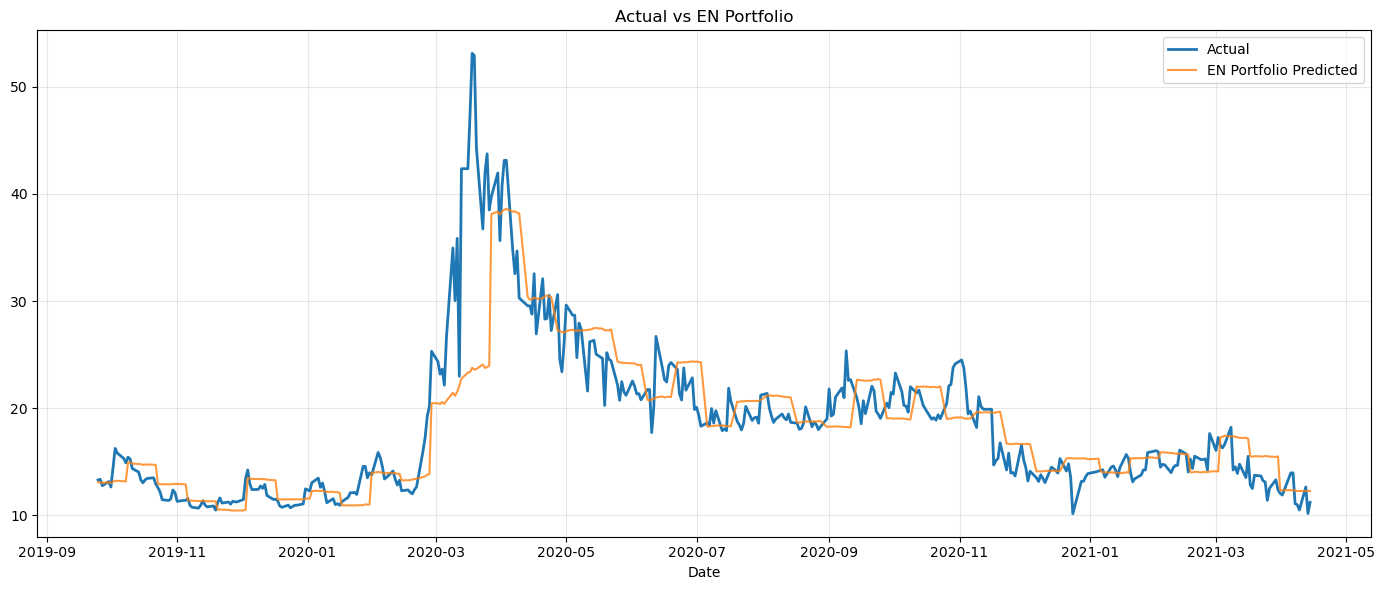

In [9]:
###################
# Elastic Net (EN)
###################

y_pred_en, y_pred_portfolio_en, reconst_en, en_components, en_coeff, en_weights, en_qp_weights, en_trading, gross_returns_en = sliding_walk_forward('EN',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en)

metrics_portfolio_en = compute_tracking_metrics('[EN] total retruns',y.iloc[pred_start:pred_end].values,gross_returns_en)
metrics_portfolio_en = compute_tracking_metrics('[EN] net retruns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en)
metrics_trading_en = compute_trading_metrics('[EN] Trading',en_trading,y_pred_portfolio_en,gross_returns_en)
en_objective = metrics_trading_en.loc[metrics_trading_en['Metric']=='net_annualised_returns', 'Value'].values[0]

if PLOT_GRAPH ==True:
    PLT_STRT = 2000 #0
    PLT_SIZE = 400  #4000
    focused_plot('EN Portfolio',reconst_en,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)
    

### **4. Hidden Markov Model**

Model design steps:
1. Feature engineering for HMM
2. Training a Hidden Markov Model (HMM)
3. Predicting hidden states from emissions
4. Estimating state prediction accuracy (hand label training set again)



In [10]:
# Fady: HMM utils
def train_hmm(emissions,n_states = HMM_STATES, covariance_type="diag", n_iter=100, random_state=SEED):

    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    init_params = "stmc"
    means_init = None

    '''
    if n_states == 3:
        # Fady: initialise A-VIX state means to low, medium and high volatility levels
        means_init = np.tile(np.mean(X,axis=0),(n_states,1))
        means_init[:,0] = [11.75,15.05,21.35]
        init_params = "stc"
    #'''
    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        random_state=random_state,
        init_params=init_params,
    )

    if means_init is not None:
        model.means_ = means_init

    model.fit(X)

    return model

def predict_states(model, emissions):
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    states = model.predict(X)

    return states

def reorder_states_by_avix_mean(states,avix_values):
    # Fady: HMM state labels are arbitrary.
    # Re-number states so state 0 has the lowest A-VIX mean and
    # state HMM_STATES-1 has the highest A-VIX mean.
    states = np.asarray(states)
    avix_values = np.asarray(avix_values)

    state_means = {}

    for state in range(HMM_STATES):
        state_values = avix_values[states == state]

        if len(state_values) > 0:
            state_means[state] = np.mean(state_values)
        else:
            state_means[state] = np.inf

    state_order = sorted(state_means,key=state_means.get)
    state_map = {old_state:new_state for new_state,old_state in enumerate(state_order)}

    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states,state_map

def apply_state_map(states,state_map):
    states = np.asarray(states)
    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states

def evaluate_state_predictions( true_states, predicted_states):
    metrics = {
        "accuracy": accuracy_score(
            true_states,
            predicted_states
        ),
        "precision_macro": precision_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            true_states,
            predicted_states,
        ),
        "classification_report": classification_report(
            true_states,
            predicted_states,
            zero_division=0,
        ),
    }

    return metrics

def plot_column_histograms( data, bins=50, figsize=(8, 5)):


    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data)

    for col in data.columns:

        plt.figure(figsize=figsize)

        plt.hist(
            data[col].dropna(),
            bins=bins,
            edgecolor="black"
        )

        plt.title(f"Histogram of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")

        plt.grid(True, alpha=0.3)

        plt.show()

def plot_series_and_states(y, states):

    if isinstance(y,pd.Series):
        dates = y.index
    else:
        dates = np.arange(len(y))

    y = np.asarray(y)
    states = np.asarray(states)

    state_transitions = int(np.sum(states[1:] != states[:-1]))
    print(f"\n\nNumber of state transitions: {state_transitions}")
    print('\n\n')

    colors = {
        0: "tab:blue",
        1: "tab:orange",
        2: "tab:green"
    }
    colors = {state:colors[state] for state in range(HMM_STATES)}

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot continuous line with segment colours determined by state
    if isinstance(dates,pd.DatetimeIndex):
        x_values = mdates.date2num(dates)
        ax1.xaxis_date()
    else:
        x_values = np.asarray(dates,dtype=float)

    segments = np.stack(
        [np.column_stack([x_values[:-1],y[:-1]]),np.column_stack([x_values[1:],y[1:]])],
        axis=1
    )
    segment_colors = [colors.get(state,"black") for state in states[:-1]]

    ax1.add_collection(LineCollection(segments,colors=segment_colors,linewidths=1.5))
    ax1.autoscale_view()

    # Dummy lines for legend
    for state, color in colors.items():
        ax1.plot([], [], color=color, linewidth=2,
                 label=f"Series (State {state})")

    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX")
    ax1.grid(True, alpha=0.3)

    # Secondary axis showing the states
    ax2 = ax1.twinx()

    ax2.step(
        dates,
        states,
        where="post",
        color="grey",
        #color="white",
        linewidth=2,
        alpha=0.8,
        linestyle="dashed",
        label="State Sequence"
    )

    ax2.set_ylabel("State")
    ax2.set_ylim(-0.5, HMM_STATES-0.5)
    ax2.set_yticks(range(HMM_STATES))

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")

    plt.title(str(HMM_STATES)+"-state HMM model")
    plt.tight_layout()
    plt.show()


# Fady: HMM basic feature engineering
# use the two main features A-VIX and ASX 200 index
def hmm_feature_engineering(prices,returns,n_states):
    df_p = prices.copy()
    df_r = returns.copy()
    clms=['^AXVI', 'STW.AX']
    df_p= df_p[clms]
    # Add returns
    df_p['^AXVI_r'] = df_r['^AXVI']
    df_p['STW.AX_r'] = df_r['STW.AX']

    # Fady: simple labeling of the training set
    # state 0 = low A-VIX, state 1 = medium A-VIX, state 2 = high A-VIX
    df_p['state'] =0

    if n_states == 3:
        df_p.loc[df_p['^AXVI']>13, 'state'] = 1
        df_p.loc[df_p['^AXVI']>17, 'state'] = 2

    if n_states == 2:
        df_p.loc[df_p['^AXVI']>16, 'state'] = 1

    # Add EMAs and rolling stats
    clms=['^AXVI', 'STW.AX','^AXVI_r','state']

    for clm in clms:
        #df_p['ema3_'+clm] = df_p[clm].ewm(span=3, adjust=False).mean()
        #df_p['ema3_'+clm].bfill(inplace=True)
        #df_p['ema3_pct_'+clm] = df_p['ema3_'+clm].pct_change()
        #df_p['ema3_pct_'+clm].bfill(inplace=True)

        df_p['ema10_'+clm] = df_p[clm].ewm(span=10, adjust=False).mean()
        df_p['ema10_'+clm].bfill(inplace=True)
        df_p['ema10_pct_'+clm] = df_p['ema10_'+clm].pct_change()
        df_p['ema10_pct_'+clm].bfill(inplace=True)

        #df_p['std10_'+clm] = df_p[clm].rolling(window=10).std()
        #df_p['std10_'+clm].bfill(inplace=True)
        #df_p['std10_pct_'+clm] = df_p['std10_'+clm].pct_change()
        #df_p['std10_pct_'+clm].bfill(inplace=True)

        #df_p['std20_'+clm] = df_p[clm].rolling(window=20).std()
        #df_p['std20_'+clm].bfill(inplace=True)
        #df_p['std20_pct_'+clm] = df_p['std20_'+clm].pct_change()
        #df_p['std20_pct_'+clm].bfill(inplace=True)

    # handle unexpected values
    for clm in df_p.columns:
        finite_values = df_p.loc[np.isfinite(df_p[clm]),clm]
        df_p[clm] = df_p[clm].replace(np.inf,finite_values.max())
        df_p[clm] = df_p[clm].replace(-np.inf,finite_values.min())


    df_p['state2'] =0
    if n_states == 3:
        df_p.loc[df_p['ema10_^AXVI']>13, 'state2'] = 1
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 2

    if n_states == 2:
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 1

    return df_p


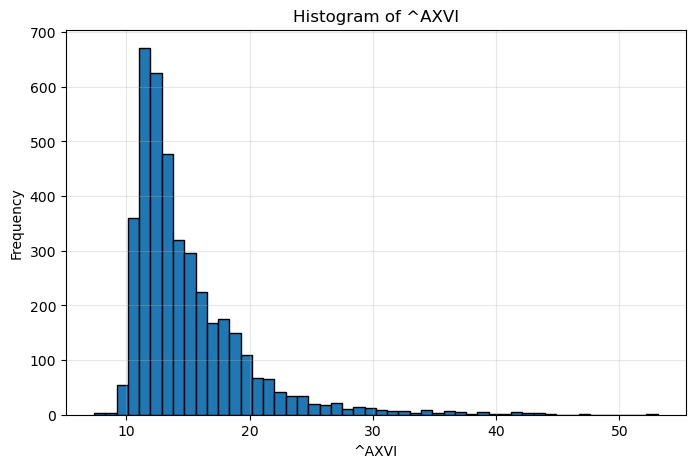

In [11]:
np.random.seed(SEED)

df_p = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)
hmm_features=['state2','ema10_state','^AXVI','ema10_^AXVI']

if PLOT_GRAPH ==True:
    plot_column_histograms(screened_prices['^AXVI'])




Number of state transitions: 156





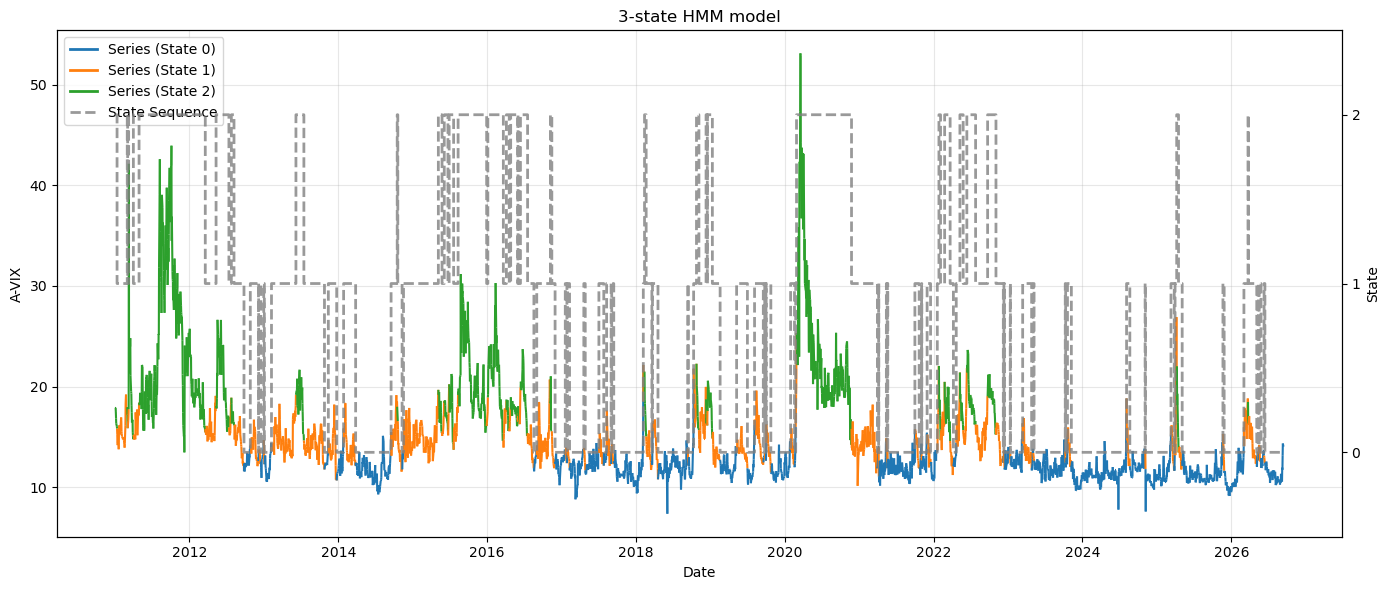


 HMM accuracy:  0.8464955577492597




{'accuracy': 0.8464955577492597,
 'precision_macro': 0.8441071910372253,
 'recall_macro': 0.84580648262666,
 'f1_macro': 0.844888790605509,
 'confusion_matrix': array([[1578,  213,    0],
        [ 176, 1042,  120],
        [   0,  113,  810]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       0.90      0.88      0.89      1791\n           1       0.76      0.78      0.77      1338\n           2       0.87      0.88      0.87       923\n\n    accuracy                           0.85      4052\n   macro avg       0.84      0.85      0.84      4052\nweighted avg       0.85      0.85      0.85      4052\n'}

In [12]:
# HMM modeling
hmm_baseline_model = train_hmm( emissions=df_p[hmm_features], n_states=HMM_STATES )
predicted_states = predict_states(  hmm_baseline_model,  df_p[hmm_features] )
predicted_states,state_map = reorder_states_by_avix_mean( predicted_states,df_p['^AXVI'].values)

df_p['pred_state'] = predicted_states

if PLOT_GRAPH ==True:
    plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])

hmm_metrics = evaluate_state_predictions(df_p['state'].values, df_p['pred_state'].values)
print('\n HMM accuracy: ', hmm_metrics['accuracy'])
print('\n')
display(hmm_metrics)
print('\n')

### **5. Expanding window Walk-forward loop for HMM**

1. Generate the train and test pairs for each iteration.
2. Fit the HMM model on the training window data
3. Apply state based EN (or PCR, PLS) fiting to training window
4. Predict the test window HMM states
5. Predict A-VIX percentage change
6. Reconstruct the A-VIX level from the predicted precentage change
7. Calculate different tracking error metrics on test window.
8. Calculate the state-based individual securties coeffcients from the factor coefficents.
9. Define state-based portfolio weight constraints guided by the regressions coeffcients after normalisation.
10. Conduct state-based QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
11. Predict portfolio returns over the test window
12. Calculate trading metrics for the rebalancing at the end of the test window

In [13]:
#Fady: implement a similar loop as the sliding window but with expanding window and state dependant models.

def expanding_hmm_states(hmm_emissions,initial_train_window_size,test_window_size):

    hmm_states = []

    splits=walk_forward_expanding_window(len(hmm_emissions), initial_train_window_size, test_window_size)

    for split in splits.itertuples():

        hmm_train = hmm_emissions[split.train_start:split.train_end + 1]
        hmm_test  = hmm_emissions[split.test_start:split.test_end + 1]

        hmm_model = train_hmm(hmm_train,n_states=HMM_STATES)
        train_states = predict_states(hmm_model,hmm_train)
        test_states = predict_states(hmm_model,hmm_test)

        # Fady: determine the state order from A-VIX means in the training
        # window only and apply the same state mapping to the test window.
        train_states,state_map = reorder_states_by_avix_mean(
            #train_states,hmm_train['^AXVI'].values
            train_states,hmm_train['ema10_^AXVI'].values
        )
        test_states = apply_state_map(test_states,state_map)

        hmm_states.append((train_states,test_states))

    return hmm_states


# Fady: expanding window loop with HMM state based models
def expanding_walk_forward(title,X_df,y_df,orig_price,hmm_states,initial_train_window_size,test_window_size,ncomponents=20):

    y_pred = []
    y_pred_portfolio = []  # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] #gross portfolio returns
    pred_states = []
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None
    previous_state = None

    splits=walk_forward_expanding_window(len(X_df), initial_train_window_size, test_window_size)

    if len(hmm_states) != len(splits):
        raise ValueError("hmm_states must contain one entry per expanding-window split.")

    for split,(train_states,test_states) in zip(splits.itertuples(),hmm_states):

        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        ypred = np.zeros(len(X_test))
        qp_weights_by_state = {}

        for state in range(HMM_STATES):
            train_mask = train_states == state
            test_mask = test_states == state

            if not np.any(test_mask):
                continue

            X_train_state = X_train.iloc[train_mask]
            y_train_state = y_train.iloc[train_mask]
            X_test_state = X_test.iloc[test_mask]

            # Fady: ElasticNetCV needs at least 3 observations for cv=3, avoid too small windows with HMM
            if len(X_train_state) < 3:
                X_train_state = X_train
                y_train_state = y_train

            # HMM_STATES and the split's rows, so these values identify the state's training rows.
            window_key = ('expanding',HMM_STATES,split.train_start,split.train_end,split.test_start,split.test_end,state)

            state_pred,coefficients,ncomponents_used = fit_predict_securities(
                title,X_train_state,y_train_state,X_test_state,ncomponents,window_key=window_key
            )

            if ncomponents_used is not None:
                pcr_ncomponents.append(ncomponents_used)

            portfolio_weights = coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=MIN_ABS_WEIGHT)

            aaa_train_state = screened_returns.loc[X_train_state.index,'AAA.AX']
            qp_weights = QP_optimize_weights(
                X_train_state,y_train_state,aaa_train_state,portfolio_weights,gross_exposure=1.0
            )
            qp_weights_by_state[state] = qp_weights.copy()

            ypred[test_mask] = state_pred

        # Fady: create one newly estimated QP portfolio-weight row for each test day.
        qp_columns = list(qp_weights.columns)
        daily_qp_weights = np.zeros((len(X_test),len(qp_columns)))

        for state,state_qp_weights in qp_weights_by_state.items():
            daily_qp_weights[test_states == state] = state_qp_weights.iloc[0].values

        # Fady: actual portfolio weights remain unchanged until a regime switch.
        # Newly estimated QP weights are only adopted on the day of a switch.
        executed_qp_weights = daily_qp_weights.copy()
        rebalance_opportunities = np.zeros(len(X_test),dtype=bool)

        if previous_qp_weights is None:
            current_weights = daily_qp_weights[0]
            rebalance_opportunities[0] = True
        else:
            current_weights = previous_qp_weights.iloc[-1].values

            if test_states[0] != previous_state:
                current_weights = daily_qp_weights[0]
                rebalance_opportunities[0] = True

        executed_qp_weights[0] = current_weights

        for day in range(1,len(X_test)):

            if test_states[day] != test_states[day-1]:
                current_weights = daily_qp_weights[day]
                rebalance_opportunities[day] = True

            executed_qp_weights[day] = current_weights

        executed_qp_weights = pd.DataFrame(executed_qp_weights,index=X_test.index,columns=qp_columns)

        trading = execute_portfolio_trading(
            executed_qp_weights,previous_qp_weights,transaction_cost=TRANSACTION_COST,
            rebalance_opportunities=rebalance_opportunities,min_rel_weight_chng=MIN_REL_WEIGHT_CHANGE
        )
        trading_records.append(trading)

        aaa_test = screened_returns.loc[X_test.index,'AAA.AX']
        ypred_portfolio,ypred_portfolio_gross = compute_portfolio_returns(
            executed_qp_weights,X_test,aaa_test,short_borrow_rate=SHORT_BORROW_RATE,
            transaction_costs=trading['transaction_cost'].values
        )

        previous_qp_weights = executed_qp_weights.iloc[[-1]].copy()
        previous_state = test_states[-1]

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))
        pred_states.extend(list(test_states))

    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, pred_states, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross




Model is not converging.  Current: -615.4719734507992 is not greater than -615.4590482859331. Delta is -0.012925164866032901
Model is not converging.  Current: -915.8313902489036 is not greater than -915.8254174822324. Delta is -0.005972766671220597
Model is not converging.  Current: -1461.1256122554116 is not greater than -1460.8411718420982. Delta is -0.28444041331340486
Model is not converging.  Current: -1476.0621270871798 is not greater than -1475.6328630695566. Delta is -0.42926401762315436
Model is not converging.  Current: -1525.1943325052139 is not greater than -1525.0688980262817. Delta is -0.12543447893222037
Model is not converging.  Current: -1555.6036675571856 is not greater than -1555.4382533716894. Delta is -0.1654141854962745
Model is not converging.  Current: -1584.11401462501 is not greater than -1583.9145898963993. Delta is -0.19942472861066562
Model is not converging.  Current: -1612.8297682028003 is not greater than -1612.6012900089468. Delta is -0.228478193853561


[PCR_HMM] net returns
------------------------------
MAE				: 0.0444
RMSE			: 0.066948
TE1_Dorocakova : 0.066957
TE2_Dorocakova : 0.044446
TE3_Dorocakova : 0.050072

[PCR_HMM] Trading
------------------------------
Annualised gross returns		: 0.003698
Annualised net returns			: -0.069543
Annualised Transaction Cost		: 0.071730
Annualised Short Borrow Cost	: 0.001512
Annualised Total Cost			: 0.073242
Turnover ratio					: 58.291588
Rebalance days					: 711
Rebalance opportunities			: 711
Number of trades				: 16398
Maximum daily turnover			: 1.686754
Average active holdings			: 18.41


<Figure size 640x480 with 0 Axes>

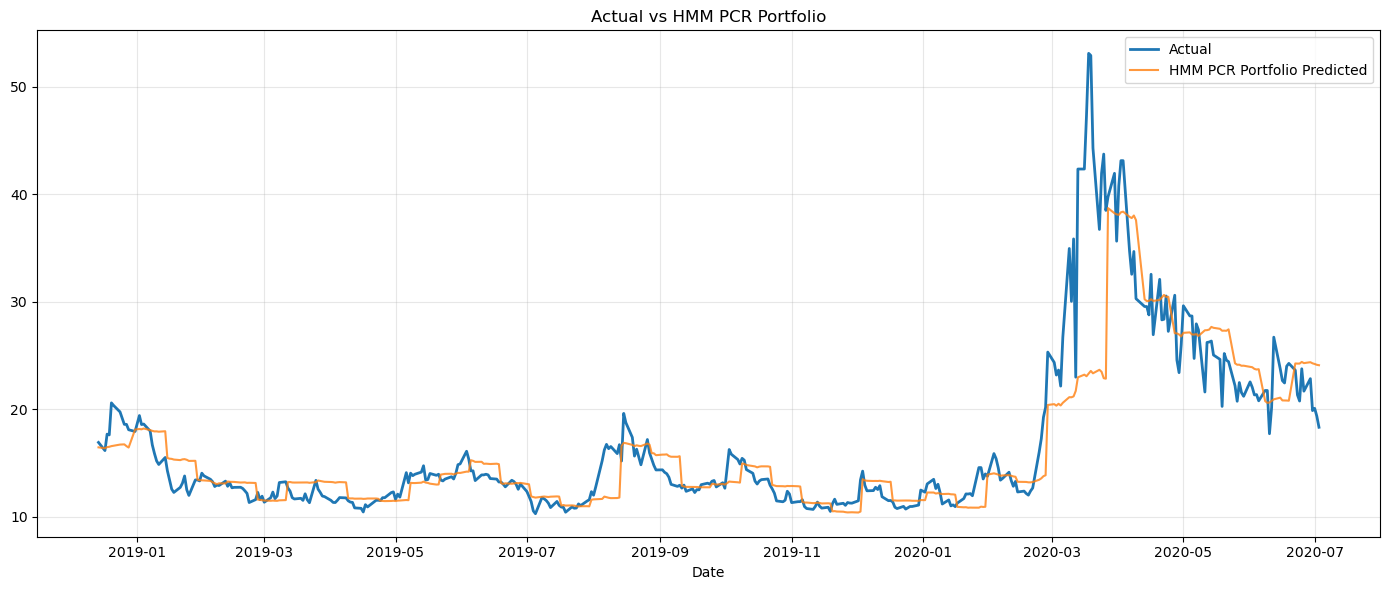

In [14]:
#########################
# Expanding HMM + PCR
#########################

hmm_emissions = df_p[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_pcr_exp, y_pred_portfolio_pcr_exp, reconst_pcr_exp, pcr_components_exp, pred_states_pcr_exp, hmm_pcr_coeff, hmm_pcr_weights, hmm_pcr_qp_weights, hmm_pcr_trading, gross_returns_pcr_exp = expanding_walk_forward(
    'PCR',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr_exp)

#metrics_portfolio_pcr_exp = compute_tracking_metrics('[PCR_HMM] total returns',y.iloc[pred_start:pred_end].values,gross_returns_pcr_exp)
metrics_portfolio_pcr_exp = compute_tracking_metrics('[PCR_HMM] net returns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_exp)
metrics_trading_pcr_exp = compute_trading_metrics('[PCR_HMM] Trading',hmm_pcr_trading,y_pred_portfolio_pcr_exp,gross_returns_pcr_exp)
pcr_exp_objective = metrics_trading_pcr_exp.loc[metrics_trading_pcr_exp['Metric']=='net_annualised_returns', 'Value'].values[0]

if PLOT_GRAPH ==True:
    PLT_STRT = 1800 #0
    PLT_SIZE = 400  #4000
    focused_plot('HMM PCR Portfolio',reconst_pcr_exp,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)


Model is not converging.  Current: -615.4719734507992 is not greater than -615.4590482859331. Delta is -0.012925164866032901
Model is not converging.  Current: -915.8313902489036 is not greater than -915.8254174822324. Delta is -0.005972766671220597
Model is not converging.  Current: -1461.1256122554116 is not greater than -1460.8411718420982. Delta is -0.28444041331340486
Model is not converging.  Current: -1476.0621270871798 is not greater than -1475.6328630695566. Delta is -0.42926401762315436
Model is not converging.  Current: -1525.1943325052139 is not greater than -1525.0688980262817. Delta is -0.12543447893222037
Model is not converging.  Current: -1555.6036675571856 is not greater than -1555.4382533716894. Delta is -0.1654141854962745
Model is not converging.  Current: -1584.11401462501 is not greater than -1583.9145898963993. Delta is -0.19942472861066562
Model is not converging.  Current: -1612.8297682028003 is not greater than -1612.6012900089468. Delta is -0.228478193853561


[PLS_HMM] net returns
------------------------------
MAE				: 0.0445
RMSE			: 0.066957
TE1_Dorocakova : 0.066966
TE2_Dorocakova : 0.044456
TE3_Dorocakova : 0.050075

[PLS_HMM] Trading
------------------------------
Annualised gross returns		: 0.003780
Annualised net returns			: -0.064790
Annualised Transaction Cost		: 0.066972
Annualised Short Borrow Cost	: 0.001598
Annualised Total Cost			: 0.068570
Turnover ratio					: 56.100894
Rebalance days					: 711
Rebalance opportunities			: 711
Number of trades				: 16866
Maximum daily turnover			: 1.595718
Average active holdings			: 17.93


<Figure size 640x480 with 0 Axes>

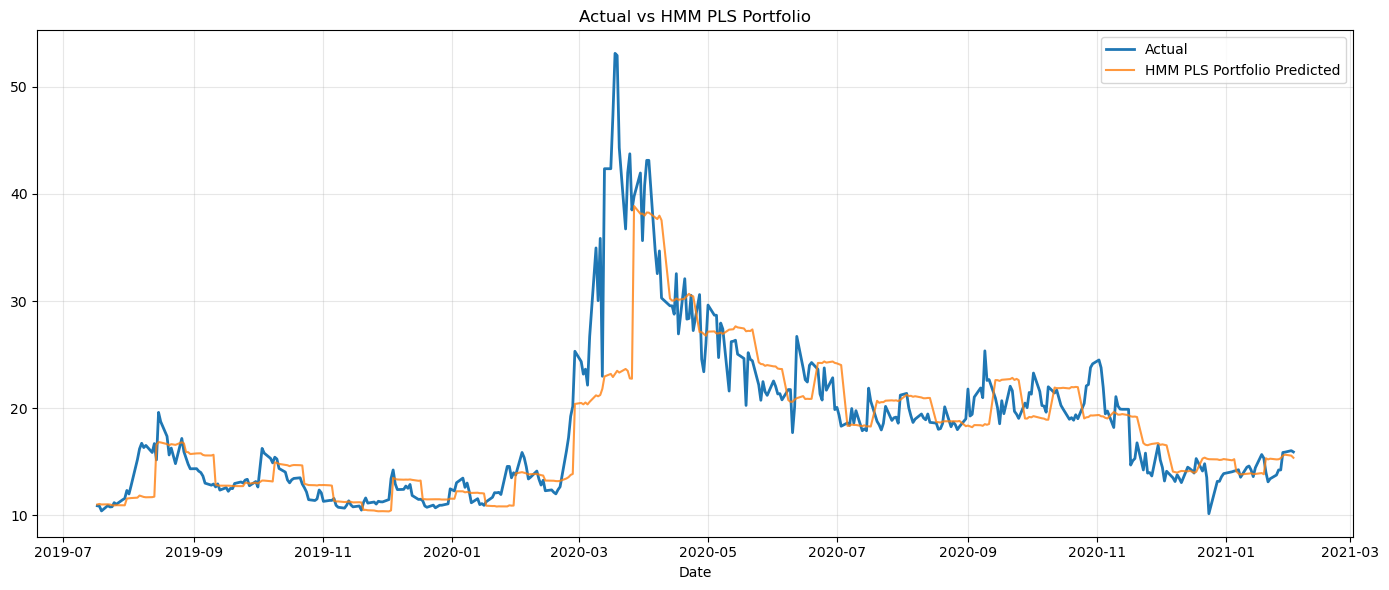

In [15]:
#########################
# Expanding HMM + PLS
#########################

hmm_emissions = df_p[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

pls_ncomponents_exp = PLS_COMPONENTS
y_pred_pls_exp, y_pred_portfolio_pls_exp, reconst_pls_exp, pls_components_exp, pred_states_pls_exp, hmm_pls_coeff, hmm_pls_weights, hmm_pls_qp_weights, hmm_pls_trading, gross_returns_pls_exp = expanding_walk_forward(
    'PLS',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,pls_ncomponents_exp)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls_exp)

#metrics_portfolio_pls_exp = compute_tracking_metrics('[PLS_HMM] total returns',y.iloc[pred_start:pred_end].values,gross_returns_pls_exp)
metrics_portfolio_pls_exp = compute_tracking_metrics('[PLS_HMM] net returns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_exp)
metrics_trading_pls_exp = compute_trading_metrics('[PLS_HMM] Trading',hmm_pls_trading,y_pred_portfolio_pls_exp,gross_returns_pls_exp)
pls_exp_objective = metrics_trading_pls_exp.loc[metrics_trading_pls_exp['Metric']=='net_annualised_returns', 'Value'].values[0]

if PLOT_GRAPH ==True:
    PLT_STRT = 1950 #0
    PLT_SIZE = 400  #4000
    focused_plot('HMM PLS Portfolio',reconst_pls_exp,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)
    

Model is not converging.  Current: -615.4719734507992 is not greater than -615.4590482859331. Delta is -0.012925164866032901
Model is not converging.  Current: -915.8313902489036 is not greater than -915.8254174822324. Delta is -0.005972766671220597
Model is not converging.  Current: -1461.1256122554116 is not greater than -1460.8411718420982. Delta is -0.28444041331340486
Model is not converging.  Current: -1476.0621270871798 is not greater than -1475.6328630695566. Delta is -0.42926401762315436
Model is not converging.  Current: -1525.1943325052139 is not greater than -1525.0688980262817. Delta is -0.12543447893222037
Model is not converging.  Current: -1555.6036675571856 is not greater than -1555.4382533716894. Delta is -0.1654141854962745
Model is not converging.  Current: -1584.11401462501 is not greater than -1583.9145898963993. Delta is -0.19942472861066562
Model is not converging.  Current: -1612.8297682028003 is not greater than -1612.6012900089468. Delta is -0.228478193853561


[EN_HMM] net returns
------------------------------
MAE				: 0.0443
RMSE			: 0.066711
TE1_Dorocakova : 0.066720
TE2_Dorocakova : 0.044310
TE3_Dorocakova : 0.049877

[EN_HMM] Trading
------------------------------
Annualised gross returns		: 0.000833
Annualised net returns			: -0.069390
Annualised Transaction Cost		: 0.068514
Annualised Short Borrow Cost	: 0.001708
Annualised Total Cost			: 0.070222
Turnover ratio					: 56.470321
Rebalance days					: 711
Rebalance opportunities			: 711
Number of trades				: 16033
Maximum daily turnover			: 1.626366
Average active holdings			: 17.05


<Figure size 640x480 with 0 Axes>

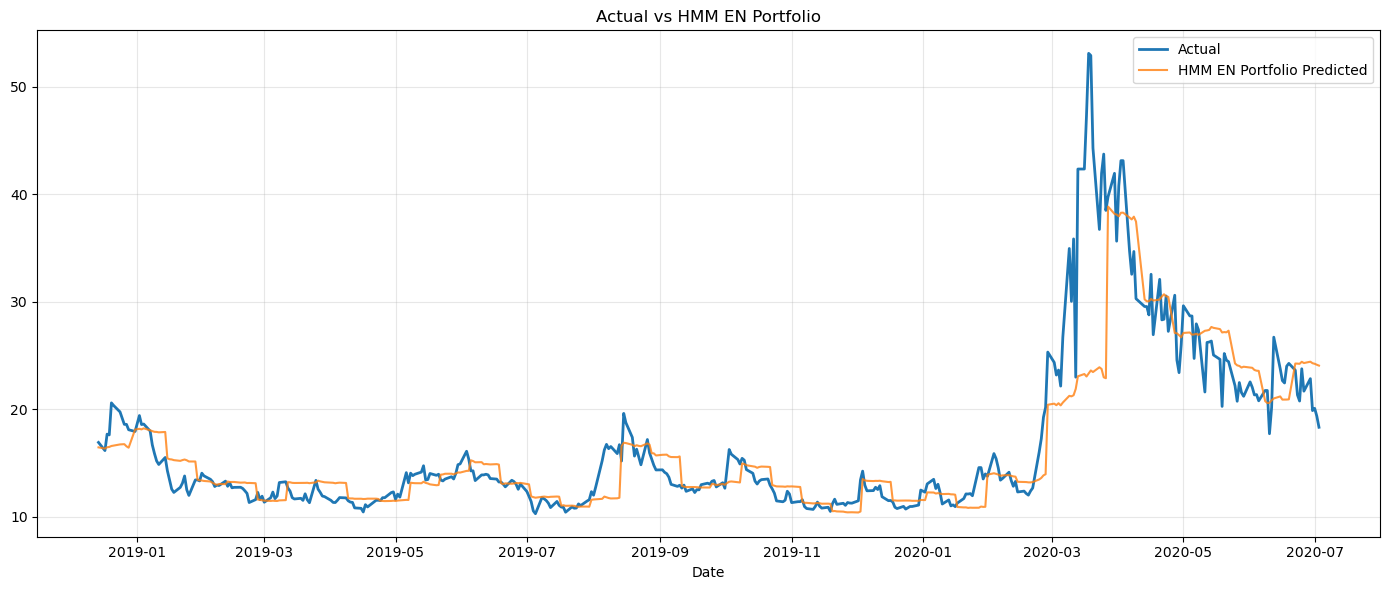

In [16]:
#########################
# Expanding HMM + Elastic Net
#########################

hmm_emissions = df_p[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_en_exp, y_pred_portfolio_en_exp, reconst_en_exp, en_components_exp, pred_states_en_exp, hmm_en_coeff, hmm_en_weights, hmm_en_qp_weights, hmm_en_trading, gross_returns_en_exp = expanding_walk_forward(
    'EN',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en_exp)

#metrics_portfolio_en_exp = compute_tracking_metrics('[EN_HMM] total returns',y.iloc[pred_start:pred_end].values,gross_returns_en_exp)
metrics_portfolio_en_exp = compute_tracking_metrics('[EN_HMM] net returns',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_exp)
metrics_trading_en_exp = compute_trading_metrics('[EN_HMM] Trading',hmm_en_trading,y_pred_portfolio_en_exp,gross_returns_en_exp)
en_exp_objective = metrics_trading_en_exp.loc[metrics_trading_en_exp['Metric']=='net_annualised_returns', 'Value'].values[0]

if PLOT_GRAPH ==True:
    PLT_STRT = 1800 #0
    PLT_SIZE = 400  #4000
    focused_plot('HMM EN Portfolio',reconst_en_exp,screened_prices['^AXVI'].iloc[pred_start:pred_end],PLT_STRT,PLT_SIZE)

